# NanoTox calssification model developemnt
Author: Chi-Yun Chen

Date: Nov 17, 2026

Description: Modeling classification task

Ensure the kernel is **Python 3 (ipykernel)

In [1]:
#Install basic python pcakges
import numpy as np
import pandas as pd

In [2]:
Cytotox = pd.read_csv('NanoTox_9338.csv')
Cytotox.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9338 entries, 0 to 9337
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Cytotoxicity       9338 non-null   object 
 1   Core               9338 non-null   object 
 2   Surf_func          9338 non-null   object 
 3   Assay_viability    9338 non-null   object 
 4   Cell_morphol       9338 non-null   object 
 5   Cell_type          9338 non-null   object 
 6   Tumor_cell         9338 non-null   object 
 7   Cell_source        9338 non-null   object 
 8   Cell_culture       9338 non-null   object 
 9   Cell_age           9338 non-null   object 
 10  Diameter           9338 non-null   float64
 11  Time               9338 non-null   float64
 12  Concentration      9338 non-null   float64
 13  Mol_weight         9338 non-null   float64
 14  Electronegativity  9338 non-null   float64
 15  Dh_median          9338 non-null   float64
 16  ZP_median          9338 

## Scenario I (Using Dh_median & ZP_median)

In [3]:
Cytotox_clean = Cytotox.drop(columns=Cytotox.columns[[17]])  

In [4]:
# Binary Encoding for columns with Number of unique values = 2 (reduce dimentionality)
Cytotox_clean['Cell_culture'] = Cytotox_clean['Cell_culture'].map({'primary': 1, 'cell_line': 0})
Cytotox_clean['Cell_age'] = Cytotox_clean['Cell_age'].map({'Embryonic': 1, 'NonEmbryonic': 0})
Cytotox_clean['Tumor_cell'] = Cytotox_clean['Tumor_cell'].map({'Yes': 1, 'No': 0})

# Classification Model

## Step 1: remove duplicated rows

In [5]:
# 1) IDENTIFY: every row that is part of an exact-duplicate set
dup_mask_all = Cytotox_clean.duplicated(keep=False)
print('rows involved in exact duplicates:', dup_mask_all.sum())

# excess copies only (this is how many rows dropping will remove)
print('rows to be removed:', Cytotox_clean.duplicated(keep='first').sum())

# inspect them grouped together before you drop anything
dup_rows = Cytotox_clean[dup_mask_all].sort_values(by=list(Cytotox_clean.columns))
print(dup_rows)

rows involved in exact duplicates: 821
rows to be removed: 507
       Cytotoxicity  Core    Surf_func Assay_viability Cell_morphol  \
7622      Cytotoxic    Ag  CCK_peptide             LDH     neuronal   
7628      Cytotoxic    Ag  CCK_peptide             LDH     neuronal   
7623      Cytotoxic    Ag  CCK_peptide             LDH     neuronal   
7629      Cytotoxic    Ag  CCK_peptide             LDH     neuronal   
7618      Cytotoxic    Ag  CCK_peptide             LDH     neuronal   
...             ...   ...          ...             ...          ...   
1436  Non_cytotoxic  SiO2   Unmodified      alamarBlue   epithelial   
1433  Non_cytotoxic  SiO2   Unmodified      alamarBlue   epithelial   
1437  Non_cytotoxic  SiO2   Unmodified      alamarBlue   epithelial   
1424  Non_cytotoxic  SiO2   Unmodified      alamarBlue     monocyte   
1428  Non_cytotoxic  SiO2   Unmodified      alamarBlue     monocyte   

                  Cell_type  Tumor_cell Cell_source  Cell_culture  Cell_age  \
7622 

In [6]:
# 2) DROP: keep the first occurrence of each set
Cytotox_dedup = Cytotox_clean.drop_duplicates(keep='first').copy()
print('before:', len(Cytotox_clean), 'after:', len(Cytotox_dedup))

before: 9338 after: 8831


## Step 2: Data preparation

In [7]:
# Columns to be transformed via one-hot encoding
encode = ["Core", "Surf_func", "Assay_viability", "Cell_morphol", "Cell_type", "Cell_source"]

# Perform one-hot encoding
Cytotox_encoded = pd.get_dummies(Cytotox_dedup, columns=encode, drop_first=True)

In [8]:
# Where 'Cell_morphol_spindle, epithelial' = True, set both columns to True
mask = Cytotox_encoded['Cell_morphol_spindle, epithelial'] == True

Cytotox_encoded.loc[mask, 'Cell_morphol_spindle'] = True
Cytotox_encoded.loc[mask, 'Cell_morphol_epithelial'] = True

# Step 2: Drop the combined column
Cytotox_encoded = Cytotox_encoded.drop(columns=['Cell_morphol_spindle, epithelial'])

In [9]:
Cytotoxicity = Cytotox_encoded.dropna()

# Map 'Non_cytotoxic' to 0 and 'Cytotoxic' to 1
Cytotoxicity.iloc[:, 0] = Cytotoxicity.iloc[:, 0].map({'Non_cytotoxic': 0, 'Cytotoxic': 1})

In [10]:
# Converts True to 1 and False to 0 wherever they appear
Cytotoxicity = Cytotoxicity.map(lambda x: int(x) if isinstance(x, bool) else x)

In [11]:
Cytotoxicity.head()

,Cytotoxicity,Tumor_cell,Cell_culture,Cell_age,Diameter,Time,Concentration,Mol_weight,Electronegativity,Dh_median,...,Cell_type_primary_microglia,Cell_type_tissue_macrophage,Cell_source_Dog,Cell_source_Hamster,Cell_source_Human,Cell_source_Monkey,Cell_source_Mouse,Cell_source_Pig,Cell_source_Rabbit,Cell_source_Rat
0,0,0,1,0,14.0,72.0,50.0,60.083,2.926667,175.5,...,0,0,0,0,1,0,0,0,0,0
1,0,0,1,0,14.0,72.0,5.0,60.083,2.926667,175.5,...,0,0,0,0,1,0,0,0,0,0
2,0,1,0,0,15.0,24.0,10.0,60.083,2.926667,590.0,...,0,0,0,0,1,0,0,0,0,0
3,0,1,0,0,15.0,24.0,50.0,60.083,2.926667,590.0,...,0,0,0,0,1,0,0,0,0,0
4,0,1,0,0,15.0,24.0,100.0,60.083,2.926667,590.0,...,0,0,0,0,1,0,0,0,0,0


## Step 3: Split dataframe to X and y

In [12]:
cY_2d = Cytotoxicity.loc[:, ['Cytotoxicity']]
# Convert Y as a column vector to a 1D array
cY = cY_2d.values.ravel()
print(cY.shape)

(8831,)


In [13]:
# X features
cX = Cytotoxicity.iloc[:, 1:288]
print(cX.shape)

(8831, 286)


In [14]:
variance = cX.var()
cX = cX.loc[:, variance != 0]

In [15]:
# Group columns with identical values
groups = []
checked = set()

for col in cX.columns:
    if col in checked:
        continue
    group = [col]
    for other_col in cX.columns:
        if other_col != col and other_col not in checked:
            if cX[col].equals(cX[other_col]):
                group.append(other_col)
    if len(group) > 1:
        groups.append(group)
        checked.update(group)

print("Groups of identical columns:")
for g in groups:
    print(g)

Groups of identical columns:
['Core_Cu', 'Surf_func_AscorbicAcid', 'Cell_type_HGF']
['Surf_func_CCK_peptide', 'Cell_type_primary mixed neurons']
['Surf_func_dansylamide', 'Cell_type_primary_microglia']
['Assay_viability_Relative_total_growth', 'Cell_type_L5178Y/Tk+/_ -3.7.2C']
['Cell_morphol_myoblast', 'Cell_type_H9c2']
['Cell_morphol_stem_cell', 'Cell_type_D3']
['Cell_type_MDCK', 'Cell_source_Dog']
['Cell_type_SIRC', 'Cell_source_Rabbit']
['Cell_type_Vero', 'Cell_source_Monkey']


In [16]:
for group in groups:
    # Keep the first, drop the rest
    cX.drop(columns=group[1:], inplace=True)

In [17]:
print(cX.shape)

(8831, 276)


In [18]:
cX.to_csv('ClassX.csv', index=False)  # download to verify the column names
cY_2d.to_csv('ClassY.csv', index=False) 

In [19]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm  # Import the colormap module
from sklearn.manifold import TSNE
from pypalettes import load_cmap
from pypalettes import create_cmap

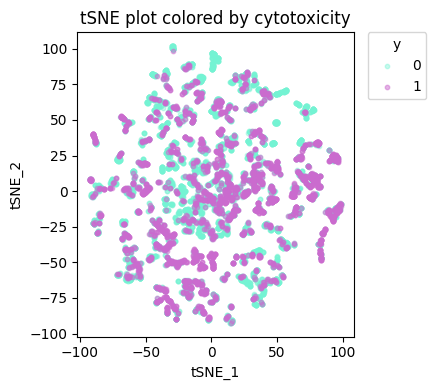

In [20]:
# Compute t-SNE embedding
tsne = TSNE(n_components=2, random_state=42)
X_embedded = tsne.fit_transform(cX)

# Plot, coloring by y=0 (mint) and y=1 (lavender)
plt.figure(figsize=(4.5, 4))
plt.scatter(X_embedded[cY==0, 0], X_embedded[cY==0, 1], color='#74F3D3FF', label='0', alpha=0.4, s=10)
plt.scatter(X_embedded[cY==1, 0], X_embedded[cY==1, 1], color='#CB6BCEFF',  label='1', alpha=0.5, s=10)
plt.legend(title='y', bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.title('tSNE plot colored by cytotoxicity')
plt.xlabel('tSNE_1')
plt.ylabel('tSNE_2')
plt.tight_layout()

plt.show()

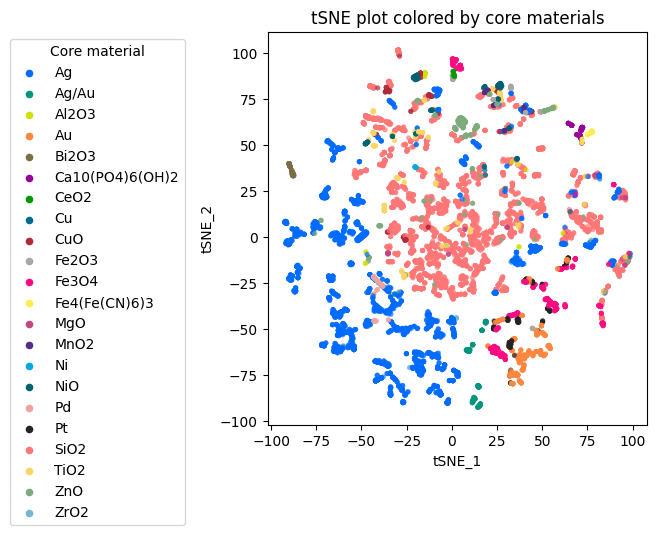

In [21]:
# Colored by core materials
# Build a 22‐color palette
core_type = Cytotox_dedup.iloc[:, 1].astype(str)   # core material category:
unique_types = sorted(core_type.unique())
cmap = create_cmap(
    colors=['#006BFFFF', '#00957EFF', '#D0E005FF', '#FD873EFF', '#7C6D46FF',   # Coris_gaimard
            '#990099FF', '#009900FF',                                          # classic
            '#006A8EFF', '#B1283AFF', '#A8A6A7FF',                             # wsj_dem_rep
            '#FD0C81FF', '#FFED4DFF', '#C34582FF', '#582C83FF', '#00A9E0FF', '#006271FF', '#EBA49EFF', '#272324FF', #"AndyWarhol_1" mixed "jazz_classic"
            '#FF7676FF', '#F9D662FF', '#7CAB7DFF', '#75B7D1FF']                # fernande
)
palette = {t: cmap(i) for i, t in enumerate(unique_types)}

# Plot
fig, ax = plt.subplots(figsize=(7, 5.3))
colors = core_type.map(palette)
ax.scatter(X_embedded[:,0], X_embedded[:,1], c=colors, s=14, edgecolors='none', alpha=0.7)

# Legend
for t, col in palette.items():
    ax.scatter([], [], color=col, label=t, s=20)
ax.legend(title='Core material', bbox_to_anchor=(-0.2, 1))

ax.set_xlabel('tSNE_1')
ax.set_ylabel('tSNE_2')
ax.set_title('tSNE plot colored by core materials')
plt.tight_layout()

plt.show()

# Step 4: Build Machine Learning Modeling Pipeline

In [22]:
!pip install imblearn
!pip install catboost

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [23]:
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from scipy.stats import loguniform, uniform, randint
import joblib
from joblib import dump, load
import warnings
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, balanced_accuracy_score, roc_curve
from sklearn.metrics import (precision_recall_curve, auc, matthews_corrcoef, f1_score, precision_score, recall_score)
import os
import json

<frozen importlib._bootstrap>:241: RuntimeWarning: numpy.ufunc size changed, may indicate binary incompatibility. Expected 216 from C header, got 232 from PyObject


#AdaBoost: moderate performance; excluded

#Decision Tree: moderate performance; excluded

DTree_parm_search = {
    'criterion': ['gini', 'entropy', 'log_loss'],  # Criteria for splitting
    'splitter': ['best', 'random'],  # Splitting strategy
    'max_depth': randint(1, 20),  # Maximum depth of the tree
    'min_samples_split': randint(2, 10),  # Minimum samples required to split
    'min_samples_leaf': randint(1, 10),  # Minimum samples required per leaf
    'max_features': [None, 'sqrt', 'log2'],  # Number of features to consider when looking for the best split
}

In [24]:
# Define hyperparameter grids

# Catboost parameter distribution for hyperparameter tuning: A gradient boosting model similar to XGBoost and LightGBM, but it often handles categorical and imbalanced data better
catboost_parm_search = {
    'iterations': randint(50, 240),          # Number of boosting iterations/trees
    'depth': randint(3, 11),                 # maximum tree depth
    'learning_rate': uniform(0.01, 0.29),    # Learning rate
    'l2_leaf_reg': uniform(1, 9),            # L2 regularization
    'bagging_temperature': uniform(0, 1),    # controls the randomness of Bayesian bootstrap sampling
    'border_count': randint(40, 260)         # Number of splits for numerical features
}

# Gradient Boosting parameter distribution for hyperparameter tuning
GB_parm_search = {
    'n_estimators': randint(50, 300),       # Number of boosting stages
    'learning_rate': uniform(0.01, 0.49),   # Shrinkage to prevent overfitting
    'max_depth': randint(2, 9),  # Maximum depth of individual estimators
    'min_samples_split': randint(2, 25),    # Minimum samples to split a node
    'min_samples_leaf': randint(1, 25),     # Minimum samples in a leaf
    'subsample': uniform(0.6, 0.4),         # Fraction of samples used for fitting
    'max_features': ['sqrt', 'log2', None]  # Number of features to consider at split
}

# RandomForest parameter distribution for hyperparameter tuning
rf_parm_search = {
    'n_estimators': randint(50, 200),     # Number of trees in the forest
    'max_depth': randint(3, 30),          # Maximum depth of the trees
    'min_samples_split': randint(2, 15),  # Minimum number of samples required to split an internal node
    'min_samples_leaf': randint(1, 15),   # Minimum number of samples required to be a leaf node
    'max_features': ['sqrt', 'log2', 0.3, 0.5, 0.7, 0.9]
}

# XGBoost parameter distribution for hyperparameter tuning
xgb_parm_search = {
    'n_estimators': randint(50, 400),         # Number of trees in the forest
    'max_depth': randint(3, 13),              # Maximum depth of trees
    'learning_rate': uniform(0.01, 0.39),     # Step size shrinkage
    'subsample': uniform(0.6, 0.4),           # Fraction of samples used for fitting
    'colsample_bytree': uniform(0.6, 0.4),    # Fraction of features used for fitting
    'gamma': uniform(0, 1),                   # Minimum loss reduction required to make a further partition
    'scale_pos_weight': uniform(1, 19)        # Adjust weight of positive class
}

# KNN parameter distribution for hyperparameter tuning
KNN_parm_search = {
    'n_neighbors': randint(2, 10),       # Number of neighbors  # avoid k=1 (overfitting)
    'weights': ['uniform', 'distance'],  # Weight function used in prediction
    'metric': ['euclidean', 'manhattan', 'chebyshev'],  # Distance metric
}

# SVC parameters distribution for hyperparameter tuning  #BALANCED takes forever
svc_parm_search = {
    'C': loguniform(1e-1, 1e2),     # Regularization parameter
    'gamma': loguniform(1e-2, 1)
}

# NN parameter distribution for hyperparameter tuning
NN_parm_search = {
    'hidden_layer_sizes': [(64,), (128,), (50,50), (100,50), (126,64), (150,100), 
                           (200, 64), (200, 150), (256, 128), (64, 50, 32)],  # different architectures: 1 hidden or 2 hidden layers
    'activation': ['logistic', 'relu', 'tanh'],  
    'alpha': np.logspace(-5, -1, 10),   # L2 regularization from 1e-4 to 1e-1
}

# Define models
models = {
    'CatBoost': (CatBoostClassifier(verbose=0, thread_count=1), catboost_parm_search),
    'GB': (GradientBoostingClassifier(), GB_parm_search),
    'RF': (RandomForestClassifier(), rf_parm_search),
    'XGB': (XGBClassifier(n_jobs=1), xgb_parm_search),  
    'KNN': (KNeighborsClassifier(), KNN_parm_search),
    'SVC': (SVC(probability=True, cache_size=1000), svc_parm_search),      # Enable probability estimates for SVC
    'NN': (MLPClassifier(max_iter=4000, early_stopping=True, n_iter_no_change=25, random_state=42), NN_parm_search)    
    }

80% train, 20% test
Cross validation by using StratifiedKFold to ensure that each fold maintains the same proportion of classes as in the original dataset

In [25]:
# Fit and transform only numerical features 
#'Diameter', 'Time', 'Concentration', 'Mol_weight', 'Electronegativity', 'Dh_median', 'ZP_median'
binary_features = [
    col for col in cX.columns
    if set(cX[col].dropna().unique()).issubset({0, 1})
]

numerical_features = [
    col for col in cX.columns
    if col not in binary_features
]

In [26]:
TREE_BASED = {"CatBoost", "GB", "RF", "XGB"}
METRIC_NAMES = (
    "accuracy", "precision", "recall", "f1", "roc_auc", "mcc", "pr_auc",
)

# Hyperparameter tuning for classical algorithms

def make_pipeline(model_name, model, param_search):
    """Tree models: no scaling. Others: numerical-only scaling, binaries passthrough."""
    if model_name in TREE_BASED:
        return model, param_search
    preprocessor = ColumnTransformer(
        transformers=[("num", StandardScaler(), numerical_features)],
        remainder="passthrough",
    )
    pipeline = Pipeline([("preprocessor", preprocessor), ("clf", model)])
    pipe_params = {f"clf__{k}": v for k, v in param_search.items()}
    return pipeline, pipe_params


def _positive_scores(model, X):
    """Positive-class score for ROC/PR: predict_proba first, else decision_function."""
    try:
        return model.predict_proba(X)[:, 1]
    except Exception:
        pass
    try:
        return np.asarray(model.decision_function(X)).ravel()
    except Exception:
        return None


def compute_metrics(y_true, y_pred, y_score):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
    }
    if y_score is not None:
        metrics["roc_auc"] = roc_auc_score(y_true, y_score)
        precision, recall, _ = precision_recall_curve(y_true, y_score)
        metrics["pr_auc"] = auc(recall, precision)
    else:
        metrics["roc_auc"] = np.nan
        metrics["pr_auc"] = np.nan
    return metrics


def nested_cv(X, y, model_name, random_state=42, n_iter=100):
    """
    Nested CV: inner loop tunes hyperparameters, outer loop evaluates.
    Returns aggregated train/test metrics (mean, std) over outer folds.
    Train metrics are in-sample (best model evaluated on its own outer train set).
    """
    model, param_search = models[model_name]
    pipeline, pipe_params = make_pipeline(model_name, model, param_search)

    outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    y_arr = np.asarray(y)

    train_metrics = {m: [] for m in METRIC_NAMES}
    test_metrics = {m: [] for m in METRIC_NAMES}
    # CatBoost in single process to avoid warnings; others use all cores.
    search_n_jobs = 1 if model_name == "CatBoost" else -1

    for train_idx, test_idx in outer_cv.split(X, y_arr):
        X_tr = X.iloc[train_idx] if hasattr(X, "iloc") else X[train_idx]
        X_te = X.iloc[test_idx] if hasattr(X, "iloc") else X[test_idx]
        y_tr, y_te = y_arr[train_idx], y_arr[test_idx]

        random_search = RandomizedSearchCV(
            pipeline,
            param_distributions=pipe_params,
            n_iter=n_iter,
            cv=inner_cv,
            scoring="f1",
            n_jobs=search_n_jobs,
            random_state=random_state,
            error_score="raise",
        )
        random_search.fit(X_tr, y_tr)
        best_model = random_search.best_estimator_

        for container, X_eval, y_eval in (
            (train_metrics, X_tr, y_tr),
            (test_metrics, X_te, y_te),
        ):
            y_pred = best_model.predict(X_eval)
            y_score = _positive_scores(best_model, X_eval)
            for metric, value in compute_metrics(y_eval, y_pred, y_score).items():
                container[metric].append(value)

    def summarize(metrics):
        return {k: (np.nanmean(v), np.nanstd(v)) for k, v in metrics.items()}

    return {"train": summarize(train_metrics), "test": summarize(test_metrics)}


def _jsonable(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.ndarray,)):
        return obj.tolist()
    return obj

In [27]:
# ---- Final run: nested CV + refit on the full data, one model per algorithm ----
# Nested CV gives an unbiased estimate, but each fold model only sees part of the
# data. Refit on the full data to get a single deployable model per algorithm.
results_list = []
best_params_all = {}

for model_name, (model, param_search) in models.items():
    print(f"Model: {model_name}")

    nested_results = nested_cv(cX, cY, model_name)

    final_pipeline, final_pipe_params = make_pipeline(model_name, model, param_search)
    inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    search_n_jobs = 1 if model_name == "CatBoost" else -1

    final_search = RandomizedSearchCV(
        estimator=final_pipeline,
        param_distributions=final_pipe_params,
        n_iter=100,
        cv=inner_cv,
        scoring="f1",
        n_jobs=search_n_jobs,
        random_state=42,
    )
    final_search.fit(cX, cY)
    final_model = final_search.best_estimator_
    final_params = final_search.best_params_
    best_params_all[model_name] = final_params
    dump(final_model, f"Cytotox276_{model_name}.joblib")

    row = {"Model": model_name, "Best Params": final_params}
    for stage in ("train", "test"):
        for metric, (mean_val, std_val) in nested_results[stage].items():
            row[f"{stage.capitalize()} {metric} Mean"] = mean_val
            row[f"{stage.capitalize()} {metric} Std"] = std_val
    results_list.append(row)

cytotoxicity_results = pd.DataFrame(results_list)
cytotoxicity_results.to_csv("Cytotox276.csv", index=False)
print(cytotoxicity_results)

with open("best_params_276.json", "w") as f:
    json.dump(best_params_all, f, indent=2, default=_jsonable)

Model: CatBoost


TBB Warning: The number of workers is currently limited to 15. The request for 95 workers is ignored. Further requests for more workers will be silently ignored until the limit changes.



Model: GB
Model: RF
Model: XGB
Model: KNN
Model: SVC
Model: NN
      Model                                        Best Params  \
0  CatBoost  {'bagging_temperature': 0.2912291401980419, 'b...   
1        GB  {'learning_rate': 0.4965527500984572, 'max_dep...   
2        RF  {'max_depth': 26, 'max_features': 0.7, 'min_sa...   
3       XGB  {'colsample_bytree': 0.6607610774049177, 'gamm...   
4       KNN  {'clf__metric': 'manhattan', 'clf__n_neighbors...   
5       SVC  {'clf__C': 50.2636672316142, 'clf__gamma': 0.1...   
6        NN  {'clf__hidden_layer_sizes': (126, 64), 'clf__a...   

   Train accuracy Mean  Train accuracy Std  Train precision Mean  \
0             0.965774            0.004722              0.961095   
1             0.973389            0.012177              0.967162   
2             0.965406            0.001967              0.963460   
3             0.973814            0.010790              0.932620   
4             0.990573            0.000462              1.000000   


# Download df for Best file use

In [48]:
Cytotox_dedup.to_csv('Cytotox276_8831.csv', index=False)

# Two-tier feature reduction (data reorganization & traditional methods)

Data: 
REDUCE the feature categories by simplifying surf_func and removing cell_type by adding other cell-related features

In [28]:
Cytotox2 = pd.read_csv('NanoTox_9338_2.csv')
Cytotox2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9338 entries, 0 to 9337
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Cytotoxicity           9338 non-null   object 
 1   Core                   9338 non-null   object 
 2   Test_indicator         9338 non-null   object 
 3   Cell_morphol           9338 non-null   object 
 4   Cell_disease           9338 non-null   object 
 5   Cell_source            9338 non-null   object 
 6   Cell_culture           9338 non-null   object 
 7   Cell_tissue_GR         9338 non-null   object 
 8   Diameter               9338 non-null   float64
 9   Time                   9338 non-null   float64
 10  Concentration          9338 non-null   float64
 11  Mol_weight             9338 non-null   float64
 12  Electronegativity      9338 non-null   float64
 13  is_Unmodified          9338 non-null   int64  
 14  is_Biological          9338 non-null   int64  
 15  is_P

In [29]:
Cytotox_clean = Cytotox2.drop(columns=Cytotox2.columns[[23, 24]])  

## Step 1: remove duplicated rows

In [30]:
# 1) IDENTIFY: every row that is part of an exact-duplicate set
dup_mask_all = Cytotox_clean.duplicated(keep=False)
print('rows involved in exact duplicates:', dup_mask_all.sum())

# excess copies only (this is how many rows dropping will remove)
print('rows to be removed:', Cytotox_clean.duplicated(keep='first').sum())

# inspect them grouped together before you drop anything
dup_rows = Cytotox_clean[dup_mask_all].sort_values(by=list(Cytotox_clean.columns))
print(dup_rows)

rows involved in exact duplicates: 1400
rows to be removed: 809
       Cytotoxicity  Core Test_indicator  Cell_morphol   Cell_disease  \
7622      Cytotoxic    Ag   LDH_activity      neuronal         normal   
7628      Cytotoxic    Ag   LDH_activity      neuronal         normal   
7623      Cytotoxic    Ag   LDH_activity      neuronal         normal   
7629      Cytotoxic    Ag   LDH_activity      neuronal         normal   
7618      Cytotoxic    Ag   LDH_activity      neuronal         normal   
...             ...   ...            ...           ...            ...   
3427  Non_cytotoxic  SiO2    tetrazolium  keratinocyte         normal   
1116  Non_cytotoxic  SiO2    tetrazolium      monocyte       leukemia   
3406  Non_cytotoxic  SiO2    tetrazolium      monocyte       leukemia   
2601  Non_cytotoxic  SiO2    tetrazolium      neuronal  neuroblastoma   
2607  Non_cytotoxic  SiO2    tetrazolium      neuronal  neuroblastoma   

     Cell_source Cell_culture Cell_tissue_GR  Diameter   Ti

In [31]:
# 2) DROP: keep the first occurrence of each set
Cytotox_dedup2 = Cytotox_clean.drop_duplicates(keep='first').copy()
print('before:', len(Cytotox_clean), 'after:', len(Cytotox_dedup2))

before: 9338 after: 8529


## Step 2: Data preparation

In [32]:
# Binary Encoding for columns with Number of unique values = 2 (reduce dimentionality)
Cytotox_dedup2['Cell_culture'] = Cytotox_dedup2['Cell_culture'].map({'primary': 1, 'cell_line': 0})

In [33]:
# Columns to be transformed via one-hot encoding
encode = ["Core", "Test_indicator", "Cell_morphol", "Cell_disease", "Cell_source", 
          "Cell_tissue_GR"]

# Perform one-hot encoding
Cytotox2_encoded = pd.get_dummies(Cytotox_dedup2, columns=encode, drop_first=True)

In [34]:
# Step 1: Where 'Cell_morphol_spindle, epithelial' = True, set both columns to True
mask = Cytotox2_encoded['Cell_morphol_spindle, epithelial'] == True

Cytotox2_encoded.loc[mask, 'Cell_morphol_spindle'] = True
Cytotox2_encoded.loc[mask, 'Cell_morphol_epithelial'] = True

# Step 2: Drop the combined column
Cytotox2_encoded = Cytotox2_encoded.drop(columns=['Cell_morphol_spindle, epithelial'])

In [35]:
Cytotoxicity2 = Cytotox2_encoded.dropna()

# Map 'Non_cytotoxic' to 0 and 'Cytotoxic' to 1
Cytotoxicity2.iloc[:, 0] = Cytotoxicity2.iloc[:, 0].map({'Non_cytotoxic': 0, 'Cytotoxic': 1})

In [36]:
# Converts True to 1 and False to 0 wherever they appear
Cytotoxicity2 = Cytotoxicity2.map(lambda x: int(x) if isinstance(x, bool) else x)

In [37]:
Cytotoxicity2.head()

,Cytotoxicity,Cell_culture,Diameter,Time,Concentration,Mol_weight,Electronegativity,is_Unmodified,is_Biological,is_PEG_Polymer,...,Cell_tissue_GR_Kidney,Cell_tissue_GR_Liver,Cell_tissue_GR_Lung,Cell_tissue_GR_Musculoskeletal,Cell_tissue_GR_Reproductive,Cell_tissue_GR_Sensory_Barrier,Cell_tissue_GR_Skin,Cell_tissue_GR_Urinary,Cell_tissue_GR_cell_hybrid,Cell_tissue_GR_umbilical_cord
0,0,1,14.0,72.0,50.0,60.083,2.926667,1,0,0,...,0,0,0,0,0,0,1,0,0,0
1,0,1,14.0,72.0,5.0,60.083,2.926667,1,0,0,...,0,0,0,0,0,0,1,0,0,0
2,0,0,15.0,24.0,10.0,60.083,2.926667,1,0,0,...,0,0,1,0,0,0,0,0,0,0
3,0,0,15.0,24.0,50.0,60.083,2.926667,1,0,0,...,0,0,1,0,0,0,0,0,0,0
4,0,0,15.0,24.0,100.0,60.083,2.926667,1,0,0,...,0,0,1,0,0,0,0,0,0,0


In [38]:
CY_2d = Cytotoxicity2.loc[:, ['Cytotoxicity']]
# Convert Y as a column vector to a 1D array
CY = CY_2d.values.ravel()
print(CY.shape)

(8529,)


In [39]:
# X features
CX2 = Cytotoxicity2.iloc[:, 1:97]
print(CX2.shape)

(8529, 95)


In [40]:
variance = CX2.var()
CX2 = CX2.loc[:, variance != 0]

In [41]:
# Group columns with identical values
groups = []
checked = set()

for col in CX2.columns:
    if col in checked:
        continue
    group = [col]
    for other_col in CX2.columns:
        if other_col != col and other_col not in checked:
            if CX2[col].equals(CX2[other_col]):
                group.append(other_col)
    if len(group) > 1:
        groups.append(group)
        checked.update(group)

print("Groups of identical columns:")
for g in groups:
    print(g)

Groups of identical columns:


In [42]:
print(CX2.shape)

(8529, 95)


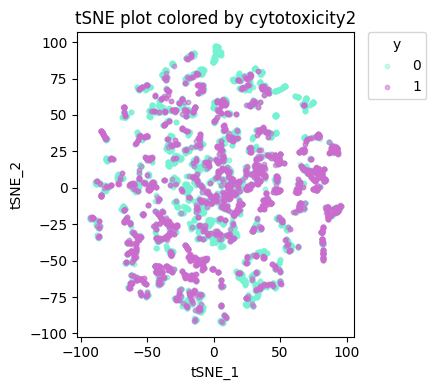

In [43]:
# Compute t-SNE embedding
tsne = TSNE(n_components=2, random_state=42)
X_embedded = tsne.fit_transform(CX2)

# Plot, coloring by y=0 (mint) and y=1 (lavender)
plt.figure(figsize=(4.5, 4))
plt.scatter(X_embedded[CY==0, 0], X_embedded[CY==0, 1], color='#74F3D3FF', label='0', alpha=0.4, s=10)
plt.scatter(X_embedded[CY==1, 0], X_embedded[CY==1, 1], color='#CB6BCEFF',  label='1', alpha=0.5, s=10)
plt.legend(title='y', bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.title('tSNE plot colored by cytotoxicity2')
plt.xlabel('tSNE_1')
plt.ylabel('tSNE_2')
plt.tight_layout()
#plt.savefig("tSNE_cytotoxicity.png", transparent=True, dpi=300, bbox_inches="tight") 
plt.show()

## Step 3: Build Machine Learning Modeling Pipeline

In [44]:
# Define models
models = {
    'CatBoost': (CatBoostClassifier(verbose=0, thread_count=1), catboost_parm_search),
    'GB': (GradientBoostingClassifier(), GB_parm_search),
    'RF': (RandomForestClassifier(), rf_parm_search),
    'XGB': (XGBClassifier(n_jobs=1), xgb_parm_search),  
    'KNN': (KNeighborsClassifier(), KNN_parm_search),
    'SVC': (SVC(probability=True, cache_size=1000), svc_parm_search),      # Enable probability estimates for SVC
    'NN': (MLPClassifier(max_iter=4000, early_stopping=True, n_iter_no_change=25, random_state=42), NN_parm_search)    
    }

In [45]:
# Fit and transform only numerical features 
#'Diameter', 'Time', 'Concentration', 'Mol_weight', 'Electronegativity', 'Dh_median', 'ZP_median'
binary_features = [
    col for col in CX2.columns
    if set(CX2[col].dropna().unique()).issubset({0, 1})
]

numerical_features = [
    col for col in CX2.columns
    if col not in binary_features
]

In [46]:
TREE_BASED = {"CatBoost", "GB", "RF", "XGB"}
METRIC_NAMES = (
    "accuracy", "precision", "recall", "f1", "roc_auc", "mcc", "pr_auc",
)

# Hyperparameter tuning for classical algorithms

def make_pipeline(model_name, model, param_search):
    """Tree models: no scaling. Others: numerical-only scaling, binaries passthrough."""
    if model_name in TREE_BASED:
        return model, param_search
    preprocessor = ColumnTransformer(
        transformers=[("num", StandardScaler(), numerical_features)],
        remainder="passthrough",
    )
    pipeline = Pipeline([("preprocessor", preprocessor), ("clf", model)])
    pipe_params = {f"clf__{k}": v for k, v in param_search.items()}
    return pipeline, pipe_params


def _positive_scores(model, X):
    """Positive-class score for ROC/PR: predict_proba first, else decision_function."""
    try:
        return model.predict_proba(X)[:, 1]
    except Exception:
        pass
    try:
        return np.asarray(model.decision_function(X)).ravel()
    except Exception:
        return None


def compute_metrics(y_true, y_pred, y_score):
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
    }
    if y_score is not None:
        metrics["roc_auc"] = roc_auc_score(y_true, y_score)
        precision, recall, _ = precision_recall_curve(y_true, y_score)
        metrics["pr_auc"] = auc(recall, precision)
    else:
        metrics["roc_auc"] = np.nan
        metrics["pr_auc"] = np.nan
    return metrics


def nested_cv(X, y, model_name, random_state=42, n_iter=100):
    """
    Nested CV: inner loop tunes hyperparameters, outer loop evaluates.
    Returns aggregated train/test metrics (mean, std) over outer folds.
    Train metrics are in-sample (best model evaluated on its own outer train set).
    """
    model, param_search = models[model_name]
    pipeline, pipe_params = make_pipeline(model_name, model, param_search)

    outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    y_arr = np.asarray(y)

    train_metrics = {m: [] for m in METRIC_NAMES}
    test_metrics = {m: [] for m in METRIC_NAMES}
    # CatBoost in single process to avoid warnings; others use all cores.
    search_n_jobs = 1 if model_name == "CatBoost" else -1

    for train_idx, test_idx in outer_cv.split(X, y_arr):
        X_tr = X.iloc[train_idx] if hasattr(X, "iloc") else X[train_idx]
        X_te = X.iloc[test_idx] if hasattr(X, "iloc") else X[test_idx]
        y_tr, y_te = y_arr[train_idx], y_arr[test_idx]

        random_search = RandomizedSearchCV(
            pipeline,
            param_distributions=pipe_params,
            n_iter=n_iter,
            cv=inner_cv,
            scoring="f1",
            n_jobs=search_n_jobs,
            random_state=random_state,
            error_score="raise",
        )
        random_search.fit(X_tr, y_tr)
        best_model = random_search.best_estimator_

        for container, X_eval, y_eval in (
            (train_metrics, X_tr, y_tr),
            (test_metrics, X_te, y_te),
        ):
            y_pred = best_model.predict(X_eval)
            y_score = _positive_scores(best_model, X_eval)
            for metric, value in compute_metrics(y_eval, y_pred, y_score).items():
                container[metric].append(value)

    def summarize(metrics):
        return {k: (np.nanmean(v), np.nanstd(v)) for k, v in metrics.items()}

    return {"train": summarize(train_metrics), "test": summarize(test_metrics)}


def _jsonable(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    if isinstance(obj, (np.ndarray,)):
        return obj.tolist()
    return obj

In [47]:
# ---- Final run: nested CV + refit on the full data, one model per algorithm ----
# Nested CV gives an unbiased estimate, but each fold model only sees part of the
# data. Refit on the full data to get a single deployable model per algorithm.
REresults = []
best_params_RE = {}

for model_name, (model, param_search) in models.items():
    print(f"Model: {model_name}")

    nested_results = nested_cv(CX2, CY, model_name)

    final_pipeline, final_pipe_params = make_pipeline(model_name, model, param_search)
    inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    search_n_jobs = 1 if model_name == "CatBoost" else -1

    final_search = RandomizedSearchCV(
        estimator=final_pipeline,
        param_distributions=final_pipe_params,
        n_iter=100,
        cv=inner_cv,
        scoring="f1",
        n_jobs=search_n_jobs,
        random_state=42,
    )
    final_search.fit(CX2, CY)
    final_model = final_search.best_estimator_
    final_params = final_search.best_params_
    best_params_RE[model_name] = final_params
    dump(final_model, f"Cytotox95_{model_name}.joblib")

    row = {"Model": model_name, "Best Params": final_params}
    for stage in ("train", "test"):
        for metric, (mean_val, std_val) in nested_results[stage].items():
            row[f"{stage.capitalize()} {metric} Mean"] = mean_val
            row[f"{stage.capitalize()} {metric} Std"] = std_val
    
    REresults.append(row)

# 4) Build and save DataFrame
cytotoxicity_results = pd.DataFrame(REresults)
cytotoxicity_results.to_csv("CytotoxRE_95.csv", index=False)
print(cytotoxicity_results)

# 5) Dump best params as JSON
with open("best_params_95.json", "w") as f:
    json.dump(best_params_RE, f, indent=2, default=_jsonable)

Model: CatBoost
Model: GB
Model: RF
Model: XGB
Model: KNN
Model: SVC
Model: NN
      Model                                        Best Params  \
0  CatBoost  {'bagging_temperature': 0.06936130087516545, '...   
1        GB  {'learning_rate': 0.31840533268627863, 'max_de...   
2        RF  {'max_depth': 25, 'max_features': 0.5, 'min_sa...   
3       XGB  {'colsample_bytree': 0.7221455441377573, 'gamm...   
4       KNN  {'clf__metric': 'manhattan', 'clf__n_neighbors...   
5       SVC  {'clf__C': 50.2636672316142, 'clf__gamma': 0.1...   
6        NN  {'clf__hidden_layer_sizes': (200, 150), 'clf__...   

   Train accuracy Mean  Train accuracy Std  Train precision Mean  \
0             0.975524            0.009475              0.968604   
1             0.971744            0.006008              0.963838   
2             0.963126            0.002122              0.958046   
3             0.974967            0.009075              0.935580   
4             0.987161            0.001039          